# MachineGuard - AI (Deep Learning)

## Objective
The objective of this project is to develop a Deep Learning-based
predictive maintenance system that analyzes machine sensor data
to predict potential machine failures. The system aims to identify
machines that may require inspection or maintenance by analyzing
their operating conditions and sensor readings. It also focuses on
detecting early warning signs of failure, reducing unexpected
machine downtime, improving operational reliability, and supporting
effective maintenance planning through data-driven predictions.

## Dataset Description
The dataset contains machine sensor readings,
failure records, machine details, and maintenance data.

## Problem Statement:
Unexpected machine failures can cause production delays
and increase maintenance costs. Traditional maintenance
methods may not identify potential failures early.
This project uses Deep Learning to predict machine failures
and support timely inspection and maintenance.

## PART 1

### Import Libraries

In [2]:
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

print("All libraries imported successfully!")

All libraries imported successfully!


### check current folder

In [3]:
print("Current folder:")
print(os.getcwd())

Current folder:
C:\Users\DELL


In [4]:
zip_path = "archive (5).zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    print(zip_ref.namelist())

['PdM_errors.csv', 'PdM_failures.csv', 'PdM_machines.csv', 'PdM_maint.csv', 'PdM_telemetry.csv']


### Extract the Dataset

In [5]:
extract_folder = "dataset"

os.makedirs(extract_folder, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

print("Dataset extracted successfully!")
print(os.listdir(extract_folder))

Dataset extracted successfully!
['PdM_errors.csv', 'PdM_failures.csv', 'PdM_machines.csv', 'PdM_maint.csv', 'PdM_telemetry.csv']


### Load the CSV files

In [6]:
data_folder = extract_folder

telemetry = pd.read_csv(
    os.path.join(data_folder, "PdM_telemetry.csv")
)

failures = pd.read_csv(
    os.path.join(data_folder, "PdM_failures.csv")
)

machines = pd.read_csv(
    os.path.join(data_folder, "PdM_machines.csv")
)

maintenance = pd.read_csv(
    os.path.join(data_folder, "PdM_maint.csv")
)

errors = pd.read_csv(
    os.path.join(data_folder, "PdM_errors.csv")
)

print("All CSV files loaded successfully!")

All CSV files loaded successfully!


### Dataset over view

In [7]:
print("Telemetry shape:", telemetry.shape)
print("Failures shape:", failures.shape)
print("Machines shape:", machines.shape)
print("Maintenance shape:", maintenance.shape)
print("Errors shape:", errors.shape)

Telemetry shape: (876100, 6)
Failures shape: (761, 3)
Machines shape: (100, 3)
Maintenance shape: (3286, 3)
Errors shape: (3919, 3)


### Disply five Records

In [8]:
display(telemetry.head())
display(failures.head())
display(machines.head())
display(maintenance.head())
display(errors.head())

,datetime,machineID,volt,rotate,pressure,vibration
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511


,datetime,machineID,failure
0,2015-01-05 06:00:00,1,comp4
1,2015-03-06 06:00:00,1,comp1
2,2015-04-20 06:00:00,1,comp2
3,2015-06-19 06:00:00,1,comp4
4,2015-09-02 06:00:00,1,comp4


,machineID,model,age
0,1,model3,18
1,2,model4,7
2,3,model3,8
3,4,model3,7
4,5,model3,2


,datetime,machineID,comp
0,2014-06-01 06:00:00,1,comp2
1,2014-07-16 06:00:00,1,comp4
2,2014-07-31 06:00:00,1,comp3
3,2014-12-13 06:00:00,1,comp1
4,2015-01-05 06:00:00,1,comp4


,datetime,machineID,errorID
0,2015-01-03 07:00:00,1,error1
1,2015-01-03 20:00:00,1,error3
2,2015-01-04 06:00:00,1,error5
3,2015-01-10 15:00:00,1,error4
4,2015-01-22 10:00:00,1,error4


In [9]:
# Dataset Information

print("TELEMETRY DATA")
print(telemetry.info())

print("\nFAILURES DATA")
print(failures.info())

print("\nMACHINES DATA")
print(machines.info())

print("\nMAINTENANCE DATA")
print(maintenance.info())

print("\nERRORS DATA")
print(errors.info())

TELEMETRY DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 876100 entries, 0 to 876099
Data columns (total 6 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   datetime   876100 non-null  object 
 1   machineID  876100 non-null  int64  
 2   volt       876100 non-null  float64
 3   rotate     876100 non-null  float64
 4   pressure   876100 non-null  float64
 5   vibration  876100 non-null  float64
dtypes: float64(4), int64(1), object(1)
memory usage: 40.1+ MB
None

FAILURES DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 761 entries, 0 to 760
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   datetime   761 non-null    object
 1   machineID  761 non-null    int64 
 2   failure    761 non-null    object
dtypes: int64(1), object(2)
memory usage: 18.0+ KB
None

MACHINES DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 c

### Check Missing Values

In [10]:
print("Telemetry Missing Values:")
print(telemetry.isnull().sum())

print("\nFailures Missing Values:")
print(failures.isnull().sum())

print("\nMachines Missing Values:")
print(machines.isnull().sum())

print("\nMaintenance Missing Values:")
print(maintenance.isnull().sum())

print("\nErrors Missing Values:")
print(errors.isnull().sum())

Telemetry Missing Values:
datetime     0
machineID    0
volt         0
rotate       0
pressure     0
vibration    0
dtype: int64

Failures Missing Values:
datetime     0
machineID    0
failure      0
dtype: int64

Machines Missing Values:
machineID    0
model        0
age          0
dtype: int64

Maintenance Missing Values:
datetime     0
machineID    0
comp         0
dtype: int64

Errors Missing Values:
datetime     0
machineID    0
errorID      0
dtype: int64


In [11]:
# Check Column Names

print("Telemetry Columns:")
print(telemetry.columns.tolist())

print("\nFailures Columns:")
print(failures.columns.tolist())

print("\nMachines Columns:")
print(machines.columns.tolist())

print("\nMaintenance Columns:")
print(maintenance.columns.tolist())

print("\nErrors Columns:")
print(errors.columns.tolist())

Telemetry Columns:
['datetime', 'machineID', 'volt', 'rotate', 'pressure', 'vibration']

Failures Columns:
['datetime', 'machineID', 'failure']

Machines Columns:
['machineID', 'model', 'age']

Maintenance Columns:
['datetime', 'machineID', 'comp']

Errors Columns:
['datetime', 'machineID', 'errorID']


In [12]:
# Convert Date Columns

telemetry["datetime"] = pd.to_datetime(telemetry["datetime"])
failures["datetime"] = pd.to_datetime(failures["datetime"])
maintenance["datetime"] = pd.to_datetime(maintenance["datetime"])
errors["datetime"] = pd.to_datetime(errors["datetime"])

print("Date columns converted successfully!")

print("\nTelemetry Date Range:")
print(telemetry["datetime"].min(), "to", telemetry["datetime"].max())

print("\nFailure Records:")
print(failures.shape)

print("\nMaintenance Records:")
print(maintenance.shape)

Date columns converted successfully!

Telemetry Date Range:
2015-01-01 06:00:00 to 2016-01-01 06:00:00

Failure Records:
(761, 3)

Maintenance Records:
(3286, 3)


In [13]:
# Sensor Data Statistics

print("Telemetry Dataset Statistics:")
display(telemetry.describe())

print("\nMachine Details:")
display(machines.describe())

print("\nFailure Records:")
display(failures.head())

print("\nMaintenance Records:")
display(maintenance.head())

Telemetry Dataset Statistics:


,datetime,machineID,volt,rotate,pressure,vibration
count,876100,876100.000000,876100.000000,876100.000000,876100.000000,876100.000000
mean,2015-07-02 18:00:00,50.500000,170.777736,446.605119,100.858668,40.385007
min,2015-01-01 06:00:00,1.000000,97.333604,138.432075,51.237106,14.877054
25%,2015-04-02 12:00:00,25.750000,160.304927,412.305714,93.498181,36.777299
50%,2015-07-02 18:00:00,50.500000,170.607338,447.558150,100.425559,40.237247
75%,2015-10-02 00:00:00,75.250000,181.004493,482.176600,107.555231,43.784938
max,2016-01-01 06:00:00,100.000000,255.124717,695.020984,185.951998,76.791072
std,NaN,28.866087,15.509114,52.673886,11.048679,5.370361



Machine Details:


,machineID,age
count,100.000000,100.000000
mean,50.500000,11.330000
std,29.011492,5.856974
min,1.000000,0.000000
25%,25.750000,6.750000
50%,50.500000,12.000000
75%,75.250000,16.000000
max,100.000000,20.000000



Failure Records:


,datetime,machineID,failure
0,2015-01-05 06:00:00,1,comp4
1,2015-03-06 06:00:00,1,comp1
2,2015-04-20 06:00:00,1,comp2
3,2015-06-19 06:00:00,1,comp4
4,2015-09-02 06:00:00,1,comp4



Maintenance Records:


,datetime,machineID,comp
0,2014-06-01 06:00:00,1,comp2
1,2014-07-16 06:00:00,1,comp4
2,2014-07-31 06:00:00,1,comp3
3,2014-12-13 06:00:00,1,comp1
4,2015-01-05 06:00:00,1,comp4


## PART 2

### Early-Warning dataset creation

In [14]:
# Create Machine Failure Dataset

# Copy telemetry data
data = telemetry.copy()

# Initially mark all records as no failure
data["failure"] = 0

# Get machine and datetime pairs where failure occurred
failure_events = failures[["datetime", "machineID"]].copy()

# Mark matching telemetry records as failure
data = data.merge(
    failure_events.assign(failure=1),
    on=["datetime", "machineID"],
    how="left",
    suffixes=("", "_event")
)

# Combine failure labels
data["failure"] = data["failure_event"].fillna(0).astype(int)

# Remove extra column
data.drop(columns=["failure_event"], inplace=True)

print("Machine failure dataset created successfully!")

print("\nDataset Shape:")
print(data.shape)

print("\nFailure Label Counts:")
print(data["failure"].value_counts())

display(data.head())

Machine failure dataset created successfully!

Dataset Shape:
(876142, 7)

Failure Label Counts:
failure
0    875381
1       761
Name: count, dtype: int64


,datetime,machineID,volt,rotate,pressure,vibration,failure
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686,0
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973,0
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847,0
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144,0
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511,0


In [15]:
# Create Early Failure Warning Labels

# Sort records by machine and time
data = data.sort_values(
    ["machineID", "datetime"]
).reset_index(drop=True)

# Create a new early warning label
data["early_warning"] = 0

# Mark sensor records within 24 hours before a failure
for _, event in failures.iterrows():
    machine_id = event["machineID"]
    failure_time = event["datetime"]

    mask = (
        (data["machineID"] == machine_id) &
        (data["datetime"] < failure_time) &
        (data["datetime"] >= failure_time - pd.Timedelta(hours=24))
    )

    data.loc[mask, "early_warning"] = 1

print("Early warning labels created!")

print("\nEarly Warning Label Counts:")
print(data["early_warning"].value_counts())

print("\nSample Records:")
display(data.head())

Early warning labels created!

Early Warning Label Counts:
early_warning
0    858958
1     17184
Name: count, dtype: int64

Sample Records:


,datetime,machineID,volt,rotate,pressure,vibration,failure,early_warning
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686,0,0
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973,0,0
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847,0,0
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144,0,0
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511,0,0


In [16]:
# Check early-warning records for each machine

print("Number of machines:", data["machineID"].nunique())

print("\nEarly warning records by machine:")
print(
    data.groupby("machineID")["early_warning"]
    .agg(["count", "sum", "mean"])
    .head(10)
)

print("\nDate range:")
print("Start:", data["datetime"].min())
print("End:", data["datetime"].max())

print("\nEarly warning records by date:")
print(
    data.loc[data["early_warning"] == 1, "datetime"]
    .dt.date.value_counts()
    .sort_index()
    .head(10)
)

Number of machines: 100

Early warning records by machine:
           count  sum      mean
machineID                      
1           8761  168  0.019176
2           8762   72  0.008217
3           8761  120  0.013697
4           8761  144  0.016436
5           8761  168  0.019176
6           8761    0  0.000000
7           8762  216  0.024652
8           8761  120  0.013697
9           8761  216  0.024655
10          8761  120  0.013697

Date range:
Start: 2015-01-01 06:00:00
End: 2016-01-01 06:00:00

Early warning records by date:
datetime
2015-01-01    342
2015-01-02     66
2015-01-03     54
2015-01-04    108
2015-01-05     48
2015-01-06     60
2015-01-07     36
2015-01-08     42
2015-01-09     48
2015-01-10     48
Name: count, dtype: int64


In [17]:
# Check original failure events

print("Total failure events:", len(failures))

print("\nFailure events by machine:")
print(failures["machineID"].value_counts().sort_index().head(15))

print("\nFirst 10 failure events:")
print(
    failures[["datetime", "machineID"]]
    .sort_values("datetime")
    .head(10)
)

print("\nLast 10 failure events:")
print(
    failures[["datetime", "machineID"]]
    .sort_values("datetime")
    .tail(10)
)

Total failure events: 761

Failure events by machine:
machineID
1      7
2      4
3      5
4      6
5      7
7     10
8      5
9      9
10     5
11     6
12     6
13    13
14     4
15     7
16    13
Name: count, dtype: int64

First 10 failure events:
               datetime  machineID
409 2015-01-02 03:00:00         56
739 2015-01-02 03:00:00         99
595 2015-01-02 03:00:00         83
430 2015-01-02 03:00:00         59
94  2015-01-02 03:00:00         16
95  2015-01-02 03:00:00         16
422 2015-01-02 03:00:00         58
107 2015-01-02 03:00:00         17
578 2015-01-02 03:00:00         80
523 2015-01-02 03:00:00         73

Last 10 failure events:
               datetime  machineID
121 2015-12-27 06:00:00         17
10  2015-12-29 06:00:00          2
714 2015-12-29 06:00:00         96
649 2015-12-30 06:00:00         88
149 2015-12-30 06:00:00         20
389 2015-12-30 06:00:00         52
709 2015-12-31 06:00:00         95
668 2015-12-31 06:00:00         90
468 2015-12-31 06:00:00 

In [18]:
# Machine Failure Analysis

print("Total Failure Events:", len(failures))

print("\nFailure Count by Machine:")
failure_count = failures["machineID"].value_counts().sort_index()
display(failure_count)

print("\nNumber of Machines:", data["machineID"].nunique())

print("\nDataset Date Range:")
print("Start:", data["datetime"].min())
print("End:", data["datetime"].max())

print("\nEarly Warning Label Counts:")
print(data["early_warning"].value_counts())

Total Failure Events: 761

Failure Count by Machine:


machineID
1       7
2       4
3       5
4       6
5       7
       ..
96      5
97      8
98     16
99     19
100     3
Name: count, Length: 98, dtype: int64


Number of Machines: 100

Dataset Date Range:
Start: 2015-01-01 06:00:00
End: 2016-01-01 06:00:00

Early Warning Label Counts:
early_warning
0    858958
1     17184
Name: count, dtype: int64


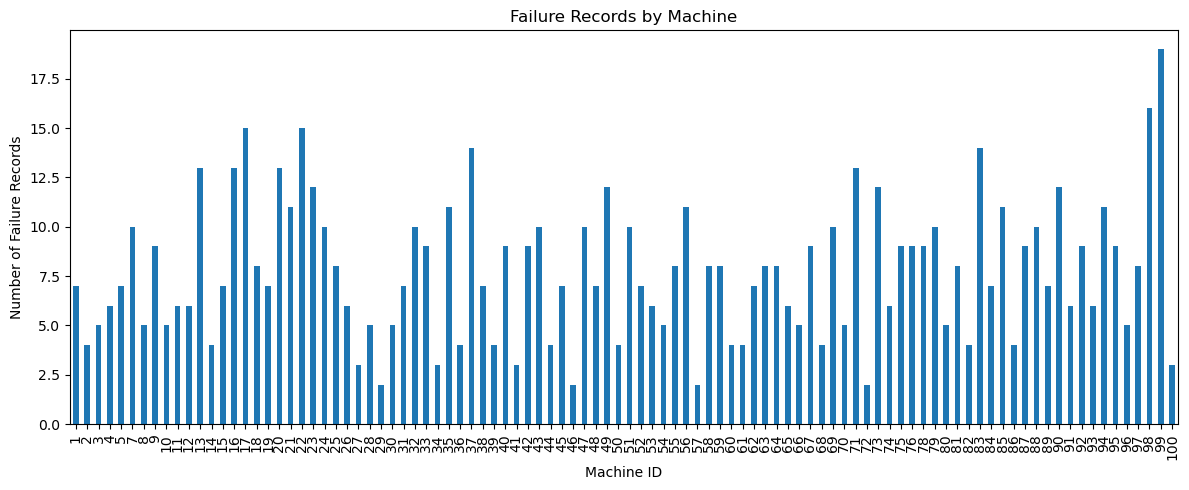

In [19]:
# Failure Count Visualization

plt.figure(figsize=(12, 5))

failure_count.plot(kind="bar")

plt.title("Failure Records by Machine")
plt.xlabel("Machine ID")
plt.ylabel("Number of Failure Records")
plt.tight_layout()
plt.show()

### Early Warning Label Counts & Check Missing Values

In [20]:
print("Total records:", len(data))

print("\nEarly Warning Label Counts:")
print(data["early_warning"].value_counts())

print("\nEarly Warning Label Percentages:")
print(data["early_warning"].value_counts(normalize=True) * 100)

print("\nMissing Values:")
print(data[["datetime", "machineID", "volt", "rotate",
            "pressure", "vibration", "early_warning"]].isnull().sum())

Total records: 876142

Early Warning Label Counts:
early_warning
0    858958
1     17184
Name: count, dtype: int64

Early Warning Label Percentages:
early_warning
0    98.038674
1     1.961326
Name: proportion, dtype: float64

Missing Values:
datetime         0
machineID        0
volt             0
rotate           0
pressure         0
vibration        0
early_warning    0
dtype: int64


In [21]:
# Compare Sensor Readings for Normal and Warning Records

sensor_features = ["volt", "rotate", "pressure", "vibration"]

print("Sensor Values by Early Warning Label:")

display(
    data.groupby("early_warning")[sensor_features]
    .agg(["mean", "median", "std"])
    .round(3)
)

Sensor Values by Early Warning Label:


volt                   rotate                  pressure  \
                  mean   median    std     mean   median     std     mean   
early_warning                                                               
0              170.675  170.528  15.44  447.164  447.976  52.269   100.77   
1              175.935  175.344  17.92  418.561  420.826  64.048   105.30   

                               vibration                 
                median     std      mean  median    std  
early_warning                                            
0              100.379  10.951    40.338  40.208  5.325  
1              103.325  14.495    42.750  42.039  6.903

In [22]:
# Create time-based sensor features

data = data.sort_values(
    ["machineID", "datetime"]
).reset_index(drop=True)

sensor_features = ["volt", "rotate", "pressure", "vibration"]

for col in sensor_features:
    data[f"{col}_mean_6h"] = (
        data.groupby("machineID")[col]
        .transform(lambda s: s.shift(1).rolling(6, min_periods=1).mean())
    )

    data[f"{col}_change_1h"] = (
        data.groupby("machineID")[col].diff()
    )

# Remove rows where previous readings are unavailable
data[sensor_features + [
    f"{col}_mean_6h" for col in sensor_features
] + [
    f"{col}_change_1h" for col in sensor_features
]].head(10)

,volt,rotate,pressure,vibration,volt_mean_6h,rotate_mean_6h,pressure_mean_6h,vibration_mean_6h,volt_change_1h,rotate_change_1h,pressure_change_1h,vibration_change_1h
0,176.217853,418.504078,113.077935,45.087686,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,162.879223,402.747490,95.460525,43.413973,176.217853,418.504078,113.077935,45.087686,-13.338630,-15.756589,-17.617410,-1.673713
2,170.989902,527.349825,75.237905,34.178847,169.548538,410.625784,104.269230,44.250829,8.110680,124.602336,-20.222621,-9.235126
3,162.462833,346.149335,109.248561,41.122144,170.028993,449.533798,94.592122,40.893502,-8.527069,-181.200490,34.010656,6.943297
4,157.610021,435.376873,111.886648,25.990511,168.137453,423.687682,98.256232,40.950662,-4.852812,89.227538,2.638087,-15.131633
5,172.504839,430.323362,95.927042,35.655017,166.031967,426.025520,100.982315,37.958632,14.894818,-5.053511,-15.959607,9.664506
6,156.556031,499.071623,111.755684,42.753920,167.110779,426.741827,100.139769,37.574696,-15.948809,68.748261,15.828643,7.098902
7,172.522781,409.624717,101.001083,35.482009,163.833808,440.169751,99.919394,37.185735,15.966750,-89.446906,-10.754602,-7.271911
8,175.324524,398.648781,110.624361,45.482287,165.441068,441.315956,100.842821,35.863741,2.801743,-10.975936,9.623278,10.000278
9,169.218423,460.850670,104.848230,39.901735,166.163505,419.865782,106.740563,37.747648,-6.106101,62.201889,-5.776131,-5.580551


In [23]:
# Define features for the improved model

base_features = [
    "volt", "rotate", "pressure", "vibration"
]

rolling_features = [
    f"{col}_mean_6h" for col in base_features
]

change_features = [
    f"{col}_change_1h" for col in base_features
]

features = base_features + rolling_features + change_features

# Remove rows where previous sensor readings are unavailable
model_data = data.dropna(
    subset=features + ["early_warning"]
).copy()

print("Original records:", len(data))
print("Records after removing NaN:", len(model_data))
print("Features:", len(features))
print("Missing values:", model_data[features].isnull().sum().sum())

Original records: 876142
Records after removing NaN: 876042
Features: 12
Missing values: 0


In [24]:
# Create Chronological Train, Validation and Test Sets

model_data = model_data.sort_values("datetime").reset_index(drop=True)

unique_dates = model_data["datetime"].sort_values().unique()

train_cutoff = unique_dates[int(len(unique_dates) * 0.64)]
val_cutoff = unique_dates[int(len(unique_dates) * 0.80)]

train_data = model_data[model_data["datetime"] < train_cutoff].copy()

val_data = model_data[
    (model_data["datetime"] >= train_cutoff) &
    (model_data["datetime"] < val_cutoff)
].copy()

test_data_new = model_data[
    model_data["datetime"] >= val_cutoff
].copy()

print("Training period:",
      train_data["datetime"].min(), "to",
      train_data["datetime"].max())

print("Validation period:",
      val_data["datetime"].min(), "to",
      val_data["datetime"].max())

print("Test period:",
      test_data_new["datetime"].min(), "to",
      test_data_new["datetime"].max())

print("\nRecords:")
print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data_new))

print("\nWarning counts:")
print("Train:", int(train_data["early_warning"].sum()))
print("Validation:", int(val_data["early_warning"].sum()))
print("Test:", int(test_data_new["early_warning"].sum()))

Training period: 2015-01-01 07:00:00 to 2015-08-22 20:00:00
Validation period: 2015-08-22 21:00:00 to 2015-10-20 06:00:00
Test period: 2015-10-20 07:00:00 to 2016-01-01 06:00:00

Records:
Train: 560628
Validation: 140205
Test: 175209

Warning counts:
Train: 11357
Validation: 2667
Test: 3141


In [25]:
# Create Chronological Train, Validation and Test Sets

model_data = model_data.sort_values(
    "datetime"
).reset_index(drop=True)

train_end = int(len(model_data) * 0.64)
val_end = int(len(model_data) * 0.80)

train_data = model_data.iloc[:train_end].copy()

val_data = model_data.iloc[train_end:val_end].copy()

test_data_new = model_data.iloc[val_end:].copy()

print("Training records:", len(train_data))
print("Validation records:", len(val_data))
print("Test records:", len(test_data_new))

Training records: 560666
Validation records: 140167
Test records: 175209


In [26]:
# Prepare Features and Scale Data

from sklearn.preprocessing import StandardScaler

X_train_new = train_data[features]
y_train_new = train_data["early_warning"]

X_val_new = val_data[features]
y_val_new = val_data["early_warning"]

X_test_new = test_data_new[features]
y_test_new = test_data_new["early_warning"]

scaler_new = StandardScaler()

X_train_new_scaled = scaler_new.fit_transform(X_train_new)
X_val_new_scaled = scaler_new.transform(X_val_new)
X_test_new_scaled = scaler_new.transform(X_test_new)

print("Training shape:", X_train_new_scaled.shape)
print("Validation shape:", X_val_new_scaled.shape)
print("Test shape:", X_test_new_scaled.shape)

print("\nScaling completed successfully.")

Training shape: (560666, 12)
Validation shape: (140167, 12)
Test shape: (175209, 12)

Scaling completed successfully.


In [52]:
# Save and Verify Scaler

import pickle
from pathlib import Path

save_path = Path(
    r"C:\Users\DELL\OneDrive\Desktop\ai_machine_prediction\machine_failure_scaler_final.pkl"
)

print("Original scaler type:", type(scaler_new))

with open(save_path, "wb") as f:
    pickle.dump(scaler_new, f)

with open(save_path, "rb") as f:
    check_scaler = pickle.load(f)

print("Saved scaler type:", type(check_scaler))

Original scaler type: <class 'sklearn.preprocessing._data.StandardScaler'>
Saved scaler type: <class 'sklearn.preprocessing._data.StandardScaler'>


### ANN model

In [28]:
# Train ANN Model with Training Data

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Calculate class weights using training data only
classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_new
)

class_weights_new = {
    0: weights[0],
    1: weights[1]
}

# Build ANN model
model_final = Sequential([
    Input(shape=(12,)),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

model_final.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Train model
history_final = model_final.fit(
    X_train_new_scaled,
    y_train_new,
    validation_data=(X_val_new_scaled, y_val_new),
    epochs=10,
    batch_size=256,
    class_weight=class_weights_new,
    verbose=1
)

Epoch 1/10
2191/2191 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.8307 - loss: 0.3255 - val_accuracy: 0.8460 - val_loss: 0.3273
Epoch 2/10
2191/2191 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8506 - loss: 0.2697 - val_accuracy: 0.8421 - val_loss: 0.3358
Epoch 3/10
2191/2191 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8522 - loss: 0.2614 - val_accuracy: 0.8609 - val_loss: 0.2766
Epoch 4/10
2191/2191 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8529 - loss: 0.2586 - val_accuracy: 0.8528 - val_loss: 0.3093
Epoch 5/10
2191/2191 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8536 - loss: 0.2552 - val_accuracy: 0.8542 - val_loss: 0.3144
Epoch 6/10
2191/2191 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8550 - loss: 0.2537 - val_accuracy: 0.8570 - val_loss: 0.2909
Epoch 7/10
2191/2191 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8556 - loss: 0.2504 - val_accuracy: 0.8627 - val_loss: 0.2893
Epoch 8/10
2191/2191 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8564 - loss: 0.2484 -

In [29]:
# ANN Model Summary

model_final.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │             832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 8,837 (34.52 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,892 (23.02 KB)

In [30]:
# Evaluate Trained ANN Model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predict probabilities on unseen test data
test_prob = model_final.predict(
    X_test_new_scaled,
    verbose=0
).ravel()

# Apply selected threshold
chosen_threshold = 0.90
test_pred = (test_prob >= chosen_threshold).astype(int)

# Calculate evaluation metrics
print("ANN MODEL EVALUATION")
print("--------------------")

print("Accuracy:", round(
    accuracy_score(y_test_new, test_pred), 4
))

print("Precision:", round(
    precision_score(y_test_new, test_pred, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test_new, test_pred, zero_division=0), 4
))

print("F1 Score:", round(
    f1_score(y_test_new, test_pred, zero_division=0), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test_new, test_prob), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_new, test_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_test_new,
    test_pred,
    labels=[0, 1],
    target_names=["Normal", "Early Warning"],
    zero_division=0
))

ANN MODEL EVALUATION
--------------------
Accuracy: 0.9742
Precision: 0.2487
Recall: 0.2168
F1 Score: 0.2317
ROC-AUC: 0.9468

Confusion Matrix:
[[170011   2057]
 [  2460    681]]

Classification Report:
               precision    recall  f1-score   support

       Normal       0.99      0.99      0.99    172068
Early Warning       0.25      0.22      0.23      3141

     accuracy                           0.97    175209
    macro avg       0.62      0.60      0.61    175209
 weighted avg       0.97      0.97      0.97    175209



In [31]:
# Select Threshold Using Validation Data

from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

val_prob = model_final.predict(
    X_val_new_scaled, verbose=0
).ravel()

print("Threshold | Precision | Recall | F1 Score")

for threshold in [0.5, 0.7, 0.8, 0.9, 0.95]:
    val_pred = (val_prob >= threshold).astype(int)

    p = precision_score(y_val_new, val_pred, zero_division=0)
    r = recall_score(y_val_new, val_pred, zero_division=0)
    f = f1_score(y_val_new, val_pred, zero_division=0)

    print(
        f"{threshold:.2f}      | {p:.3f}     | "
        f"{r:.3f}  | {f:.3f}"
    )

Threshold | Precision | Recall | F1 Score
0.50      | 0.119     | 0.970  | 0.212
0.70      | 0.131     | 0.948  | 0.230
0.80      | 0.140     | 0.907  | 0.242
0.90      | 0.252     | 0.204  | 0.226
0.95      | 0.323     | 0.015  | 0.029


In [32]:
# Validation Result Comparison

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Predict probabilities using validation data
val_prob = model_final.predict(
    X_val_new_scaled, verbose=0
).ravel()

# Compare different thresholds
threshold_results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:

    val_pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": round(
            precision_score(y_val_new, val_pred, zero_division=0), 4
        ),
        "Recall": round(
            recall_score(y_val_new, val_pred, zero_division=0), 4
        ),
        "F1 Score": round(
            f1_score(y_val_new, val_pred, zero_division=0), 4
        ),
        "Warnings Found": int(val_pred.sum())
    })

# Display comparison results
threshold_df = pd.DataFrame(threshold_results)

print("Validation Result Comparison")
print(threshold_df.to_string(index=False))

Validation Result Comparison
 Threshold  Precision  Recall  F1 Score  Warnings Found
       0.1     0.0871  0.9925    0.1602           30374
       0.2     0.0988  0.9876    0.1797           26648
       0.3     0.1065  0.9835    0.1923           24618
       0.4     0.1129  0.9775    0.2024           23099
       0.5     0.1188  0.9700    0.2118           21767
       0.6     0.1248  0.9606    0.2209           20531
       0.7     0.1312  0.9475    0.2305           19260
       0.8     0.1399  0.9074    0.2424           17302
       0.9     0.2516  0.2043    0.2255            2166


In [33]:
# Final Evaluation on Unseen Test Data

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)

chosen_threshold = 0.90

test_prob = model_final.predict(
    X_test_new_scaled, verbose=0
).ravel()

test_pred = (test_prob >= chosen_threshold).astype(int)

print("Final Threshold:", chosen_threshold)
print("Precision:", round(
    precision_score(y_test_new, test_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test_new, test_pred, zero_division=0), 4
))
print("F1 Score:", round(
    f1_score(y_test_new, test_pred, zero_division=0), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_test_new, test_prob), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_new, test_pred))

Final Threshold: 0.9
Precision: 0.2487
Recall: 0.2168
F1 Score: 0.2317
ROC-AUC: 0.9468

Confusion Matrix:
[[170011   2057]
 [  2460    681]]


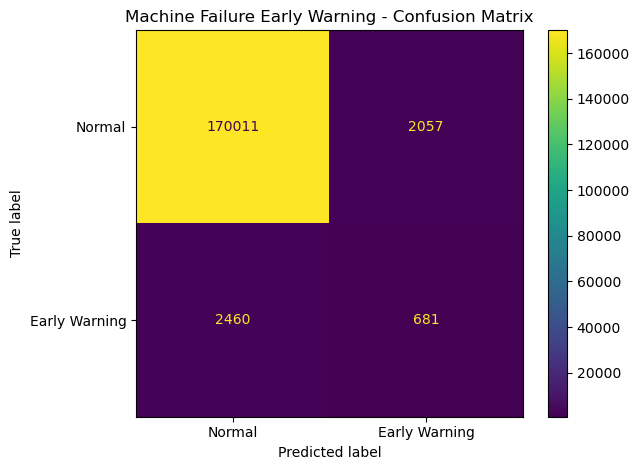

In [34]:
# Machine Failure Early Warning - Confusion Matrix

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(
    y_test_new,
    test_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Early Warning"]
)

disp.plot(values_format="d")
plt.title("Machine Failure Early Warning - Confusion Matrix")
plt.tight_layout()
plt.show()

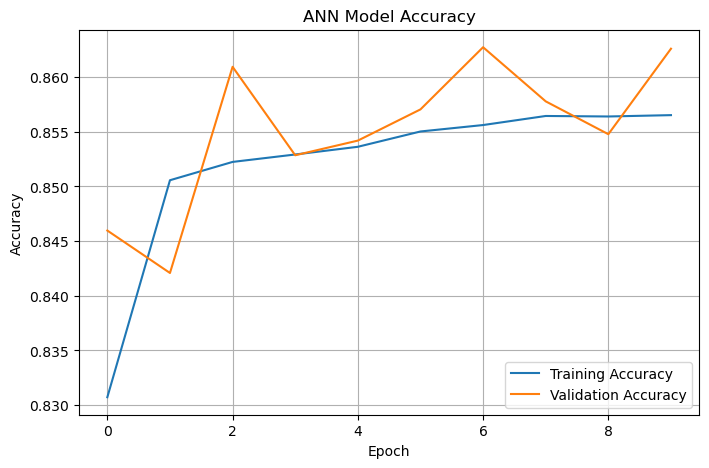

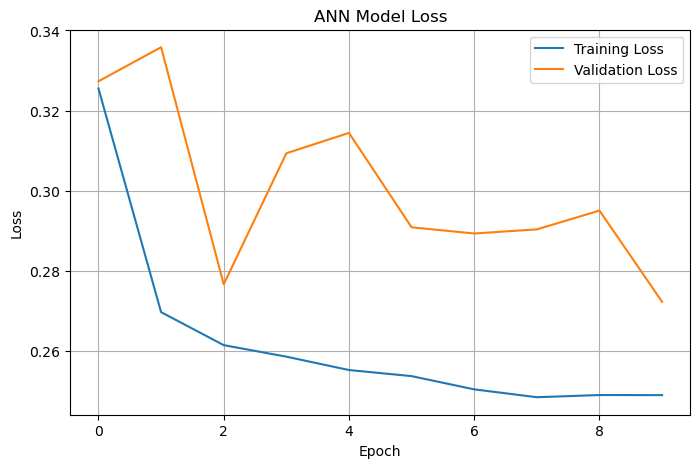

In [35]:
# Plot Training and Validation Accuracy

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history_final.history["accuracy"], label="Training Accuracy")
plt.plot(history_final.history["val_accuracy"], label="Validation Accuracy")

plt.title("ANN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()


# Plot Training and Validation Loss

plt.figure(figsize=(8, 5))

plt.plot(history_final.history["loss"], label="Training Loss")
plt.plot(history_final.history["val_loss"], label="Validation Loss")

plt.title("ANN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [36]:
# Save Final Model Files

import joblib
import os

model_final.save("machine_failure_model_final.keras")

joblib.dump(
    scaler_new,
    "machine_failure_scaler_final.pkl"
)

joblib.dump(
    features,
    "machine_failure_features_final.pkl"
)

print("Files saved successfully!")

print(os.path.exists("machine_failure_model_final.keras"))
print(os.path.exists("machine_failure_scaler_final.pkl"))
print(os.path.exists("machine_failure_features_final.pkl"))

Files saved successfully!
True
True
True


In [37]:
# Test the Saved ANN Model

import joblib
import numpy as np
from tensorflow.keras.models import load_model

# Load saved model, scaler, and features
loaded_model = load_model("machine_failure_model_final.keras")
loaded_scaler = joblib.load("machine_failure_scaler_final.pkl")
loaded_features = joblib.load("machine_failure_features_final.pkl")

# Select one test record
sample_data = X_test_new.iloc[[0]]

# Scale the sample data
sample_scaled = loaded_scaler.transform(sample_data[loaded_features])

# Predict warning probability
warning_probability = loaded_model.predict(
    sample_scaled, verbose=0
)[0][0]

chosen_threshold = 0.90

print("Warning Probability:", round(float(warning_probability), 4))

if warning_probability >= chosen_threshold:
    print("Prediction: Early Warning")
else:
    print("Prediction: No Early Warning")

Warning Probability: 0.8586
Prediction: No Early Warning


## PART 3

### Machine Wise Early Warning Analysis

In [38]:
# Machine-wise Warning Analysis

test_results = test_data_new[["machineID", "datetime"]].copy()

test_results["actual_warning"] = y_test_new.to_numpy()
test_results["warning_probability"] = test_prob

test_results["predicted_warning"] = (
    test_results["warning_probability"] >= chosen_threshold
).astype(int)

machine_summary = (
    test_results.groupby("machineID")
    .agg(
        total_records=("machineID", "size"),
        warning_records=("predicted_warning", "sum"),
        highest_warning_score=("warning_probability", "max")
    )
    .reset_index()
)

machine_summary = machine_summary.sort_values(
    by="warning_records",
    ascending=False
)

print("Top 10 Machines Requiring Attention:")
display(machine_summary.head(10))

Top 10 Machines Requiring Attention:


,machineID,total_records,warning_records,highest_warning_score
82,83,1753,80,0.966115
14,15,1753,79,0.957628
15,16,1752,76,0.976026
67,68,1752,74,0.948236
87,88,1753,70,0.941078
84,85,1752,69,0.947482
55,56,1752,68,0.951104
62,63,1752,68,0.943684
65,66,1752,67,0.950458
85,86,1752,66,0.982308


In [39]:
# Check whether each failure event has warning records
# in the preceding 24 hours

results = []

for _, event in failures.iterrows():
    machine_id = event["machineID"]
    failure_time = event["datetime"]

    previous_records = data[
        (data["machineID"] == machine_id) &
        (data["datetime"] < failure_time) &
        (data["datetime"] >= failure_time - pd.Timedelta(hours=24))
    ]

    results.append({
        "machineID": machine_id,
        "failure_time": failure_time,
        "records_before_failure": len(previous_records),
        "warning_records": int(previous_records["early_warning"].sum())
    })

failure_check = pd.DataFrame(results)

print("Total failure events:", len(failure_check))
print("Events with 24-hour records:", 
      (failure_check["records_before_failure"] > 0).sum())
print("Events with warning records:",
      (failure_check["warning_records"] > 0).sum())

print("\nFirst 10 results:")
print(failure_check.head(10).to_string(index=False))

Total failure events: 761
Events with 24-hour records: 761
Events with warning records: 761

First 10 results:
 machineID        failure_time  records_before_failure  warning_records
         1 2015-01-05 06:00:00                      24               24
         1 2015-03-06 06:00:00                      24               24
         1 2015-04-20 06:00:00                      24               24
         1 2015-06-19 06:00:00                      24               24
         1 2015-09-02 06:00:00                      24               24
         1 2015-10-17 06:00:00                      24               24
         1 2015-12-16 06:00:00                      24               24
         2 2015-03-19 06:00:00                      24               24
         2 2015-03-19 06:00:00                      24               24
         2 2015-04-18 06:00:00                      24               24


In [40]:
# Maintenance Action Recommendation

def recommend_action(score):
    if score >= 0.95:
        return "Urgent inspection recommended"
    elif score >= 0.90:
        return "Schedule maintenance inspection"
    elif score >= 0.80:
        return "Monitor sensor readings"
    else:
        return "Normal monitoring"

machine_summary["recommended_action"] = (
    machine_summary["highest_warning_score"]
    .apply(recommend_action)
)

print("Machine-wise Maintenance Recommendations:")

display(
    machine_summary[
        [
            "machineID",
            "warning_records",
            "highest_warning_score",
            "recommended_action"
        ]
    ].head(10)
)

Machine-wise Maintenance Recommendations:


,machineID,warning_records,highest_warning_score,recommended_action
82,83,80,0.966115,Urgent inspection recommended
14,15,79,0.957628,Urgent inspection recommended
15,16,76,0.976026,Urgent inspection recommended
67,68,74,0.948236,Schedule maintenance inspection
87,88,70,0.941078,Schedule maintenance inspection
84,85,69,0.947482,Schedule maintenance inspection
55,56,68,0.951104,Urgent inspection recommended
62,63,68,0.943684,Schedule maintenance inspection
65,66,67,0.950458,Urgent inspection recommended
85,86,66,0.982308,Urgent inspection recommended


In [42]:
# Check an Individual Machine

machine_id = int(input("Enter Machine ID: "))

selected_machine = machine_summary[
    machine_summary["machineID"] == machine_id
]

if not selected_machine.empty:
    row = selected_machine.iloc[0]

    print("\nMachine ID:", machine_id)
    print("Warning Records:", row["warning_records"])
    print("Highest Warning Score:",
          round(row["highest_warning_score"], 4))
    print("Recommended Action:",
          row["recommended_action"])
else:
    print("Machine ID not found.")

Enter Machine ID:  6



Machine ID: 6
Warning Records: 4
Highest Warning Score: 0.9083
Recommended Action: Schedule maintenance inspection


In [43]:
# Check Actual Failure Events in Test Period

test_start = test_data_new["datetime"].min()
test_end = test_data_new["datetime"].max()

print("Test Period:")
print("Start:", test_start)
print("End:", test_end)

failures_in_test = failures[
    (failures["datetime"] >= test_start) &
    (failures["datetime"] <= test_end)
].copy()

print("\nActual Failure Events in Test Period:",
      len(failures_in_test))

display(failures_in_test.head(10))

Test Period:
Start: 2015-10-20 07:00:00
End: 2016-01-01 06:00:00

Actual Failure Events in Test Period: 140


,datetime,machineID,failure
6,2015-12-16 06:00:00,1,comp4
10,2015-12-29 06:00:00,2,comp2
15,2015-12-03 06:00:00,3,comp2
28,2015-11-20 06:00:00,5,comp1
37,2015-10-21 06:00:00,7,comp2
38,2015-12-20 06:00:00,7,comp1
51,2015-11-14 06:00:00,9,comp1
52,2015-12-14 06:00:00,9,comp2
63,2015-12-16 06:00:00,11,comp3
79,2015-10-23 06:00:00,13,comp1


In [44]:
# Check Whether 24-Hour History Exists

test_start = test_data_new["datetime"].min()

failures_in_test["has_full_24h_history"] = (
    failures_in_test["datetime"] - pd.Timedelta(hours=24)
    >= test_start
)

print("Total Failure Events:", len(failures_in_test))

print(
    "Events with Full 24-Hour History:",
    int(failures_in_test["has_full_24h_history"].sum())
)

print(
    "Events Without Full 24-Hour History:",
    int((~failures_in_test["has_full_24h_history"]).sum())
)

display(
    failures_in_test[
        ["machineID", "datetime", "failure",
         "has_full_24h_history"]
    ].head(10)
)

Total Failure Events: 140
Events with Full 24-Hour History: 137
Events Without Full 24-Hour History: 3


,machineID,datetime,failure,has_full_24h_history
6,1,2015-12-16 06:00:00,comp4,True
10,2,2015-12-29 06:00:00,comp2,True
15,3,2015-12-03 06:00:00,comp2,True
28,5,2015-11-20 06:00:00,comp1,True
37,7,2015-10-21 06:00:00,comp2,False
38,7,2015-12-20 06:00:00,comp1,True
51,9,2015-11-14 06:00:00,comp1,True
52,9,2015-12-14 06:00:00,comp2,True
63,11,2015-12-16 06:00:00,comp3,True
79,13,2015-10-23 06:00:00,comp1,True


In [45]:
# Check Early Warning Before Actual Failures

threshold = 0.9
detected_events = []

for _, event in failures_in_test.iterrows():
    machine_id = event["machineID"]
    failure_time = event["datetime"]

    # Records from the same machine in the 24 hours before failure
    previous_records = test_results[
        (test_results["machineID"] == machine_id) &
        (test_results["datetime"] < failure_time) &
        (test_results["datetime"] >=
         failure_time - pd.Timedelta(hours=24))
    ]

    warning_found = (
        previous_records["warning_probability"] >= threshold
    ).any()

    detected_events.append({
        "machineID": machine_id,
        "failure_time": failure_time,
        "failure_type": event["failure"],
        "warning_detected": warning_found
    })

event_results = pd.DataFrame(detected_events)

print("Total Failure Events:", len(event_results))
print("Events with Prior Warning:",
      int(event_results["warning_detected"].sum()))
print("Events without Prior Warning:",
      int((~event_results["warning_detected"]).sum()))

print("\nFailure Event Detection Rate:",
      round(event_results["warning_detected"].mean() * 100, 2), "%")

display(event_results.head(10))

Total Failure Events: 140
Events with Prior Warning: 76
Events without Prior Warning: 64

Failure Event Detection Rate: 54.29 %


,machineID,failure_time,failure_type,warning_detected
0,1,2015-12-16 06:00:00,comp4,False
1,2,2015-12-29 06:00:00,comp2,True
2,3,2015-12-03 06:00:00,comp2,True
3,5,2015-11-20 06:00:00,comp1,True
4,7,2015-10-21 06:00:00,comp2,True
5,7,2015-12-20 06:00:00,comp1,False
6,9,2015-11-14 06:00:00,comp1,False
7,9,2015-12-14 06:00:00,comp2,False
8,11,2015-12-16 06:00:00,comp3,False
9,13,2015-10-23 06:00:00,comp1,True


In [46]:
# Calculate Early Warning Lead Time

lead_time_results = []

for _, event in failures_in_test.iterrows():
    machine_id = event["machineID"]
    failure_time = event["datetime"]

    previous_records = test_results[
        (test_results["machineID"] == machine_id) &
        (test_results["datetime"] < failure_time) &
        (test_results["datetime"] >=
         failure_time - pd.Timedelta(hours=24))
    ].sort_values("datetime")

    warning_records = previous_records[
        previous_records["warning_probability"] >= 0.9
    ]

    if not warning_records.empty:
        first_warning_time = warning_records["datetime"].iloc[0]

        hours_before_failure = (
            failure_time - first_warning_time
        ).total_seconds() / 3600

        lead_time_results.append({
            "machineID": machine_id,
            "failure_time": failure_time,
            "failure_type": event["failure"],
            "first_warning_time": first_warning_time,
            "hours_before_failure": hours_before_failure
        })

lead_time_df = pd.DataFrame(lead_time_results)

print("Failures with prior warning:", len(lead_time_df))

if not lead_time_df.empty:
    print("Average warning lead time (hours):",
          round(lead_time_df["hours_before_failure"].mean(), 2))

    display(lead_time_df.head(10))

Failures with prior warning: 76
Average warning lead time (hours): 19.72


,machineID,failure_time,failure_type,first_warning_time,hours_before_failure
0,2,2015-12-29 06:00:00,comp2,2015-12-28 06:00:00,24.0
1,3,2015-12-03 06:00:00,comp2,2015-12-02 10:00:00,20.0
2,5,2015-11-20 06:00:00,comp1,2015-11-19 09:00:00,21.0
3,7,2015-10-21 06:00:00,comp2,2015-10-20 07:00:00,23.0
4,13,2015-10-23 06:00:00,comp1,2015-10-22 13:00:00,17.0
5,13,2015-12-22 06:00:00,comp1,2015-12-21 06:00:00,24.0
6,13,2015-12-22 06:00:00,comp2,2015-12-21 06:00:00,24.0
7,15,2015-11-01 06:00:00,comp2,2015-10-31 06:00:00,24.0
8,15,2015-11-01 06:00:00,comp4,2015-10-31 06:00:00,24.0
9,15,2015-12-31 06:00:00,comp4,2015-12-30 06:00:00,24.0


In [47]:
# Calculate Detection Rate with Full History Only

valid_events = event_results.merge(
    failures_in_test[
        ["machineID", "datetime", "failure",
         "has_full_24h_history"]
    ],
    left_on=["machineID", "failure_time", "failure_type"],
    right_on=["machineID", "datetime", "failure"],
    how="inner"
)

valid_events = valid_events[
    valid_events["has_full_24h_history"]
].copy()

total_valid = len(valid_events)
detected_valid = int(valid_events["warning_detected"].sum())
missed_valid = total_valid - detected_valid

rate_valid = (
    detected_valid / total_valid * 100
    if total_valid > 0 else 0
)

print("Failure Events with Full 24-Hour History:", total_valid)
print("Events with Prior Warning:", detected_valid)
print("Events without Prior Warning:", missed_valid)
print("Corrected Event Detection Rate:", round(rate_valid, 2), "%")

Failure Events with Full 24-Hour History: 137
Events with Prior Warning: 73
Events without Prior Warning: 64
Corrected Event Detection Rate: 53.28 %


In [48]:
# Final Project Evaluation Summary

total_events = len(event_results)
detected_events_count = int(
    event_results["warning_detected"].sum()
)
missed_events_count = total_events - detected_events_count

detection_rate = (
    detected_events_count / total_events * 100
    if total_events else 0
)

average_lead_time = (
    lead_time_df["hours_before_failure"].mean()
    if not lead_time_df.empty else 0
)

print("=" * 45)
print("PREDICTIVE MAINTENANCE - MODEL SUMMARY")
print("=" * 45)

print("Model: Improved Artificial Neural Network (ANN)")
print("Input Features:", len(features))
print("Warning Threshold: 0.90")
print("Test Failure Events:", total_events)
print("Events with Prior Warning:", detected_events_count)
print("Events without Prior Warning:", missed_events_count)
print("Event Detection Rate:", round(detection_rate, 2), "%")
print("Average Warning Lead Time:",
      round(average_lead_time, 2), "hours")

print("=" * 45)
print("Note: Results are preliminary and require validation.")

PREDICTIVE MAINTENANCE - MODEL SUMMARY
Model: Improved Artificial Neural Network (ANN)
Input Features: 12
Warning Threshold: 0.90
Test Failure Events: 140
Events with Prior Warning: 76
Events without Prior Warning: 64
Event Detection Rate: 54.29 %
Average Warning Lead Time: 19.72 hours
Note: Results are preliminary and require validation.


## Conclusion:
This project demonstrates the application of Deep Learning
techniques for predictive maintenance and machine failure
prediction. By analyzing machine sensor data and operating
conditions, the system aims to identify potential machine
failures before they occur. The Artificial Neural Network
(ANN) model learns patterns from historical data and predicts
the possibility of machine failure based on the input features.
The system also aims to help identify machine records that may
require further inspection or maintenance. By integrating the
trained model with a Streamlit dashboard, users can interact
with the system, view sensor information, and understand the
predicted failure risk. This approach can support early warning,
reduce unexpected downtime, improve maintenance planning, and
enhance machine reliability. Overall, the project demonstrates
how Deep Learning and data-driven analysis can support more
efficient predictive maintenance. The predictions should be
validated with appropriate data before being used for actual
industrial maintenance decisions.